# 7 · Recommend: "today's ocean looks like these days in history"

**Syllabus:** Module 5 (content-based filtering, similarity, evaluating recommenders).

A shop recommends products similar to the one you are viewing. Forecasters have long
done the same thing with weather: find past days that looked like today (**analog
days**), and see what happened next. Here the "products" are days, and the
"description" of each day is what satellites saw of the whole North Indian Ocean that
day.

**The recommender:** given a day in 2023–2024, recommend the 5 most similar days from
2010–2022.

**Content-based, not collaborative.** Collaborative filtering recommends using other
users' ratings ("people who liked this also liked..."). Days have no users and no
ratings. They have content, so content-based filtering is the method that fits.

**How we judge it, fixed in advance:** a recommendation is only useful if the
recommended days are also similar **below** the surface, which the recommender never
saw. So each recommended day is scored by the RMSE between its 50–200 m temperature
field and the query day's, using GLORYS. Lower is better. It is compared against two
simple strategies: a random day, and the same calendar date in another year.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import common as C

C.style()
z = np.load(C.DATA / "ocean_states.npz")
days = pd.to_datetime(z["days"])
split = z["split"]
pcs = z["surface_pcs"].astype(float)
sub = z["subsurface"].astype(float)
explained = z["surface_explained"]
print(f"{len(days):,} days, each described by {pcs.shape[1]} numbers "
      f"(principal components of {int(np.round(explained.sum() * 100))}% of the surface variance)")
C.record("recommend.days", len(days)); C.record("recommend.pcs", pcs.shape[1])
C.record("recommend.pcs_explained_pct", round(float(explained.sum() * 100), 1))

5,428 days, each described by 30 numbers (principal components of 70% of the surface variance)


## 7.1 Describing a day

The satellite picture of one day is 8 maps of about 1,000 water cells each, roughly
8,000 numbers. PCA compresses them to 30 numbers that keep most of the variation. The
PCA was fitted on 2010–2020 only. The first few components mostly track the seasons,
because the monsoon is the biggest change the ocean goes through each year.

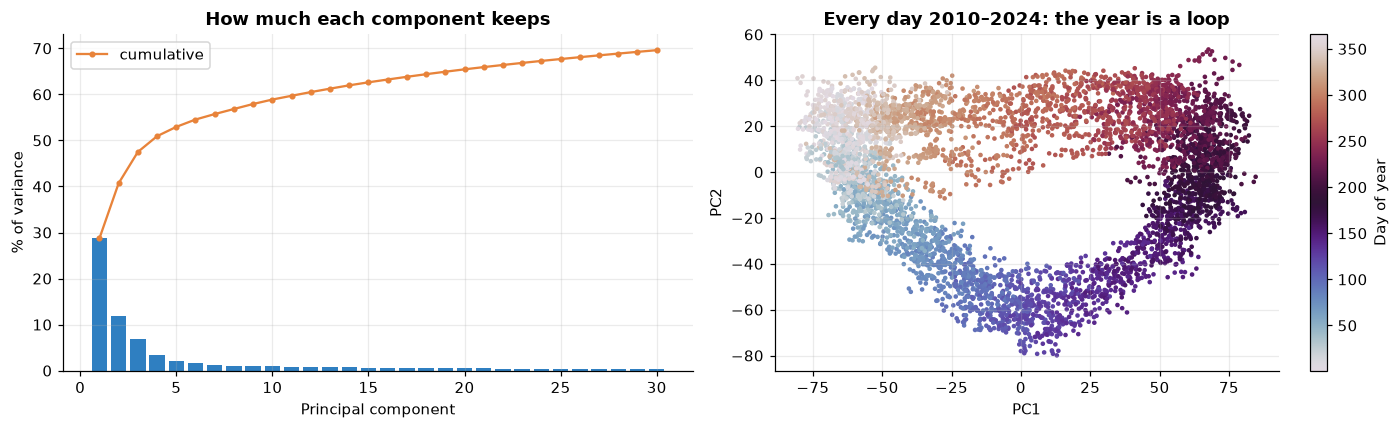

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(range(1, 31), explained * 100, color=C.PALETTE["course"])
axes[0].plot(range(1, 31), np.cumsum(explained) * 100, color=C.PALETTE["deep"], marker=".", label="cumulative")
axes[0].set_xlabel("Principal component"); axes[0].set_ylabel("% of variance"); axes[0].legend(); axes[0].set_title("How much each component keeps")
sc = axes[1].scatter(pcs[:, 0], pcs[:, 1], c=days.dayofyear, cmap="twilight", s=4)
plt.colorbar(sc, ax=axes[1], label="Day of year")
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2"); axes[1].set_title("Every day 2010–2024: the year is a loop")
fig.tight_layout(); C.save(fig, "recommend_pca")

## 7.2 Similarity: cosine

**Cosine similarity** between two days is the cosine of the angle between their
30-number descriptions: 1 means they point the same way (the same pattern), 0 means
unrelated, −1 means opposite. It ignores overall size and compares the *pattern*.

In [3]:
unit = pcs / np.linalg.norm(pcs, axis=1, keepdims=True)
query = np.flatnonzero(split == "test")
history = np.flatnonzero(np.isin(split, ["train", "val"]))
cos = unit[query] @ unit[history].T                                            # (queries, history)
K = 5
top = np.argsort(-cos, axis=1)[:, :K]
rec = history[top]


def sub_rmse(i, j):
    return np.sqrt(np.mean((sub[i] - sub[j]) ** 2, axis=-1))


rmse_rec = sub_rmse(query[:, None], rec)                                        # (queries, K)

# Baselines
rng = np.random.default_rng(C.SEED)
rand = history[rng.integers(0, len(history), size=(len(query), K))]
rmse_rand = sub_rmse(query[:, None], rand)
doy = days.dayofyear.to_numpy()
cal = []
for q in query:
    cand = history[np.abs(((doy[history] - doy[q] + 182) % 365) - 182) == 0]
    cal.append(rng.choice(cand, K, replace=len(cand) < K))
cal = np.array(cal)
rmse_cal = sub_rmse(query[:, None], cal)

# Relevance for precision@5: among all history days, the 5% most similar below the surface.
# 20 query days at a time: all at once would hold queries × history × cells numbers (about 14 GB).
all_rmse = np.concatenate([sub_rmse(query[i:i + 20, None], history[None, :]) for i in range(0, len(query), 20)])
cut = np.percentile(all_rmse, 5, axis=1, keepdims=True)
relevant = lambda r: (r <= cut).mean()
evalt = pd.DataFrame({
    "Strategy": ["Cosine similarity on the surface (recommender)", "Same calendar date, another year", "Random day"],
    "Subsurface RMSE of recommended days (°C)": [rmse_rec.mean(), rmse_cal.mean(), rmse_rand.mean()],
    "Precision@5": [relevant(rmse_rec), relevant(rmse_cal), relevant(rmse_rand)],
    "Best possible (oracle) RMSE (°C)": [np.sort(all_rmse, axis=1)[:, :K].mean()] * 3,
}).round(3)
win = (rmse_rec.mean(axis=1) < rmse_cal.mean(axis=1)).mean()
C.record("recommend.evaluation", evalt.to_dict("records"))
C.record("recommend.beats_calendar_pct_of_days", round(100 * win, 1))
print(f"The recommender beats 'same calendar date' on {win:.0%} of the {len(query)} query days")
evalt

The recommender beats 'same calendar date' on 85% of the 714 query days


,Strategy,Subsurface RMSE of recommended days (°C),Precision@5,Best possible (oracle) RMSE (°C)
0,Cosine similarity on the surface (recommender),1.182,0.705,1.022
1,"Same calendar date, another year",1.405,0.313,1.022
2,Random day,1.935,0.048,1.022


**Precision@5:** of the 5 recommended days, what share is truly relevant? A day counts
as relevant if it is among the 5% of all historical days most similar to the query
below the surface. A random pick gets about 5% by chance.

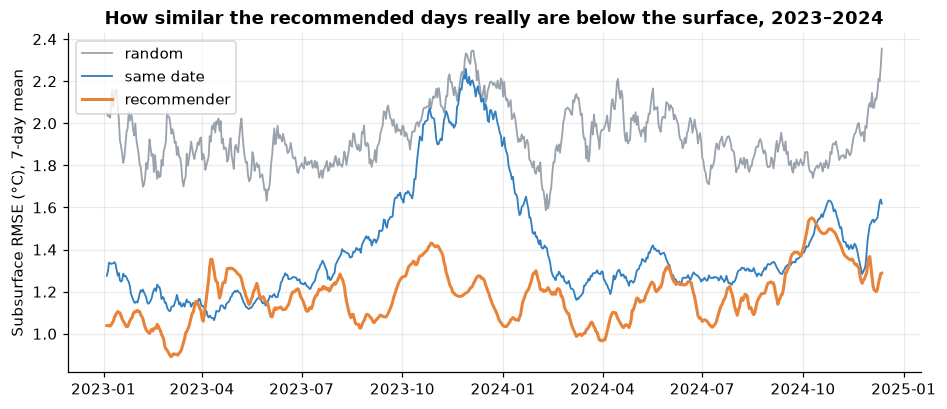

In [4]:
fig, ax = plt.subplots(figsize=(10, 4))
m = pd.DataFrame({"recommender": rmse_rec.mean(1), "same date": rmse_cal.mean(1), "random": rmse_rand.mean(1)}, index=days[query])
for col, c in [("random", C.PALETTE["climatology"]), ("same date", C.PALETTE["course"]), ("recommender", C.PALETTE["deep"])]:
    ax.plot(m.index, m[col].rolling(7, center=True).mean(), color=c, label=col, lw=2 if col == "recommender" else 1.2)
ax.set_ylabel("Subsurface RMSE (°C), 7-day mean"); ax.set_title("How similar the recommended days really are below the surface, 2023–2024")
ax.legend()
C.save(fig, "recommend_over_time")

## 7.3 A second description of a day: Satelight's learned embedding

Satelight's deep model compresses each day into its own learned summary (192 numbers),
trained to be useful for predicting the subsurface. Does it make a better
recommender? Embeddings exist only for 2023–2024, so this comparison recommends within
those two years. To stop the recommender cheating with yesterday and tomorrow, which
are always similar, **days within ±30 days of the query are excluded**.

In [5]:
emb_days = pd.to_datetime(z["embedding_days"])
emb = z["embedding"].astype(float)
pos = pd.Series(np.arange(len(days)), index=days)
idx = pos.reindex(emb_days).to_numpy()
ok = ~np.isnan(idx)
idx = idx[ok].astype(int); emb = emb[ok]
emb_c = emb - emb.mean(0)
reps = {"Surface PCA (30)": unit[idx], "Satelight embedding (192)": emb_c / np.linalg.norm(emb_c, axis=1, keepdims=True)}
gap = np.abs(idx[:, None] - idx[None, :]) <= 30
out = {}
for name, u in reps.items():
    s = u @ u.T
    s[gap] = -np.inf
    t = np.argsort(-s, axis=1)[:, :K]
    out[name] = sub_rmse(idx[:, None], idx[t]).mean()
allowed = ~gap
r = np.array([rng.choice(np.flatnonzero(a), K) for a in allowed])
out["Random day (outside ±30)"] = sub_rmse(idx[:, None], idx[r]).mean()
cmp2 = pd.Series(out, name="Subsurface RMSE of recommended days (°C)").round(3)
C.record("recommend.within_2023_2024", cmp2.to_dict())
cmp2.to_frame()

,Subsurface RMSE of recommended days (°C)
Surface PCA (30),1.285
Satelight embedding (192),1.455
Random day (outside ±30),1.968


## 7.4 Try it: Cyclone Mocha

Cyclone Mocha formed in the Bay of Bengal on 9 May 2023 (IMD). Which past days did the
ocean look like that day?

In [6]:
qd = pd.Timestamp("2023-05-09")
qi = np.flatnonzero(days[query] == qd)[0]
show = pd.DataFrame({"recommended day": days[rec[qi]].date, "cosine similarity": cos[qi, top[qi]].round(3),
                     "subsurface RMSE (°C)": rmse_rec[qi].round(3)})
C.record("recommend.mocha_example", {"query": str(qd.date()), "analogs": show.astype(str).to_dict("records")})
show

,recommended day,cosine similarity,subsurface RMSE (°C)
0,2021-04-26,0.858,1.246
1,2020-05-06,0.850,1.232
2,2021-04-25,0.850,1.262
3,2021-04-13,0.844,1.262
4,2021-04-24,0.844,1.294


## 7.5 For the dashboard

The top 10 recommendations for every day of 2023–2024 are saved, so the dashboard can
show them offline.

In [7]:
top10 = np.argsort(-cos, axis=1)[:, :10]
table = {str(days[q].date()): [{"day": str(days[history[j]].date()), "cos": round(float(cos[n, j]), 4),
                                "rmse": round(float(sub_rmse(q, history[j])), 3)} for j in top10[n]]
         for n, q in enumerate(query)}
(C.ROOT / "results" / "analogs.json").write_text(json.dumps(table), encoding="utf-8")
print(f"Saved {len(table)} query days")

Saved 714 query days
